In [1]:
# Base di calcolo presenze di combinazioni di numeri in un intervallo storico di estrazioni della lotteria

# Il codice analizza le estrazioni della lotteria per determinare la frequenza di presenza di combinazioni di numeri in un intervallo storico, 
# utilizzando una base di calcolo rappresentata da una specifica estrazione.
# Il codice è strutturato per esaminare combinazioni di numeri da 1 a 6, calcolando la frequenza media di presenza per ciascuna classe di combinazioni 
# e fornendo un riassunto dei risultati.
# Il codice utilizza la libreria Lotteria per caricare le estrazioni, numpy per la manipolazione dei dati, itertools per generare le combinazioni 
# e scipy.special.comb per calcolare i coefficienti binomiali.     
#
# Il codice carica un file CSV contenente le estrazioni della lotteria, seleziona una base di calcolo (la prima estrazione) e un 
# intervallo storico (le estrazioni successive alla base).
# Per ogni classe di combinazioni (da 1 a 6 numeri), il codice calcola le combinazioni possibili della base, 
# conta quante volte ciascuna combinazione appare nell'intervallo storico e calcola la frequenza media di presenza per ogni classe di combinazioni. 
# Infine, stampa i risultati riassuntivi per ogni classe di combinazioni, inclusi
# il numero totale di presenze, il numero di combinazioni con almeno una presenza, la massima frequenza di presenza e la frequenza media.
# 
# Nota: il codice utilizza la libreria Lotteria per caricare le estrazioni, numpy per la manipolazione dei dati, 
# itertools per generare le combinazioni e scipy.special.comb per calcolare i coefficienti binomiali.
#
# Il file CSV deve essere formattato correttamente con le estrazioni della lotteria, e il percorso del file deve essere specificato correttamente nella variabile `file_estrazione`.
# 
# Esempio di output:
# base
# [1, 2, 3, 4, 5, 6]
# Combinazioni di classe 1:
# - Presenze: [10, 15, 20, 25, 30, 35]
# - Valori riassuntivi: [135, 6, 35, 22.5]
# Combinazioni di classe 2:
# - Presenze: [5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75]
# - Valori riassuntivi: [600, 15, 75, 40.0]
# ...   
from lotteria import Lotteria
import numpy as np
from itertools import combinations
from scipy.special import comb
from scipy import stats
import matplotlib.pyplot as plt
from rebase_lib import RebaseLib

def print_dati_grafico(s,i):    
    for j in range(0,4):
        vx = [x[j] for x in s]
        print(f"\nElenco colonna {j+1} per classe k {i+1}:")
        (uniq, freq) = (np.unique(vx, return_counts=True))
        print(np.column_stack((uniq,freq)))
        
def  draw_histogram(data, k, description):
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.hist(data, bins=20, color='blue', edgecolor='black', alpha=0.7)
    ax.set_title(f'Histogram of {description} - Class {k+1}')
    ax.set_xlabel(f'{description}')
    ax.set_ylabel('Frequency')
    ax.grid(axis='y', alpha=0.5)
    plt.tight_layout()
    plt.show()

##############################################################################

file_estrazione = "./data/estrazioni_2026_2006.csv"
ll = Lotteria(file_estrazione)
rl = RebaseLib()

# Popolazione
storico_estrazioni = ll.carica_storico() # Carica le estrazioni da un file CSV
# Intervalli di campionamento
size_campione = 60

# Frequenza presenze per intervallo di campionamento   
print("Calcolo presenze per ogni base:")     
presenze = rl.calcolo_presenze(storico_estrazioni, size_campione)
print("Basi analizzate:", len(storico_estrazioni) - size_campione)

#  Sommario dei risultati per ogni classe di combinazioni
print(f"\nPresenze su s={len(storico_estrazioni)} estrazioni \nper campioni di ampiezza alfa={size_campione}:")
sommari = rl.calcolo_sommari(presenze)

# Stampa dei risultati riassuntivi per ogni classe di combinazioni
print ("\nAnalisi evidenze: (U(k), V(k), W(k), Y(k))") 
rl.statistiche_sommari(sommari)
        
        #print(f"    Somma dei sommari filtrati per classe k={i+1}: {risultato}")
        #print(f"    Copertura percentuale: {copertura}")
        
print("\nsommario completo.")

# Histogram
# descr = ['Totale Presenze', 'Combinazioni con almeno una presenza', 'Combinazioni senza presenze', 'Massima frequenza di presenza'] 
# for k in range(0,2):
#     for j in range(0,4):
#         data_column = [s[j] for s in sommari[k]]
#         draw_histogram(data_column, k, descr[j])

        

Calcolo presenze per ogni base:
Basi analizzate: 3193

Presenze su s=3253 estrazioni 
per campioni di ampiezza alfa=60:

Analisi evidenze: (U(k), V(k), W(k), Y(k))

Valori per estratto singolo
- mean    : [23.95  5.91  0.09  6.52]
- median  : [24.  6.  0.  6.]
- mode    : [24  6  0  6], [ 278 2913 2913  915]
- std     : [4.49 0.3  0.3  1.45]
- skewness: [ 0.13 -3.36  3.36  0.51]
- q1      : [21.  6.  0.  6.]
- q3      : [27.  6.  0.  7.]
  Distribuzione asimmetrica: 
  (media e deviazione standard):
    Totale presenze                      [range U(k)]: 19.0 .. 28.0, copertura: 68.1%
    Combinazioni con almeno una presenza [range V(k)]: 6.0 .. 6.0, copertura: 92.65%
    Combinazioni senza presenze          [range W(k)]: -0.0 .. 0.0, copertura: 0.0%
    Massima frequenza di presenza        [range Y(k)]: 5.0 .. 8.0, copertura: 52.28%
  (quartili):
    Totale presenze                      [range U(k)]: 21.0 .. 27.0, copertura: 55.85%
    Combinazioni con almeno una presenza [range V(k)]:

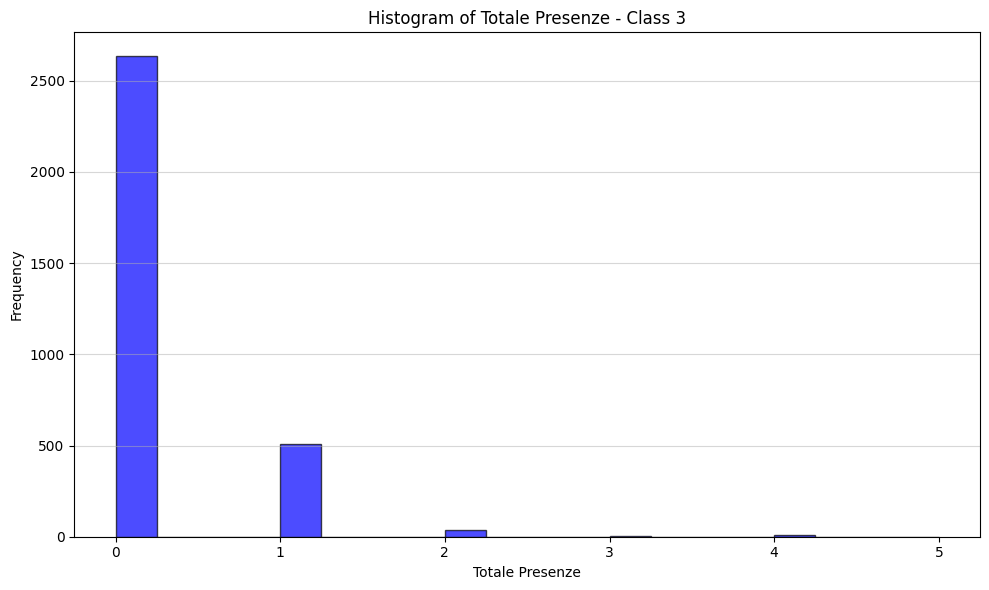

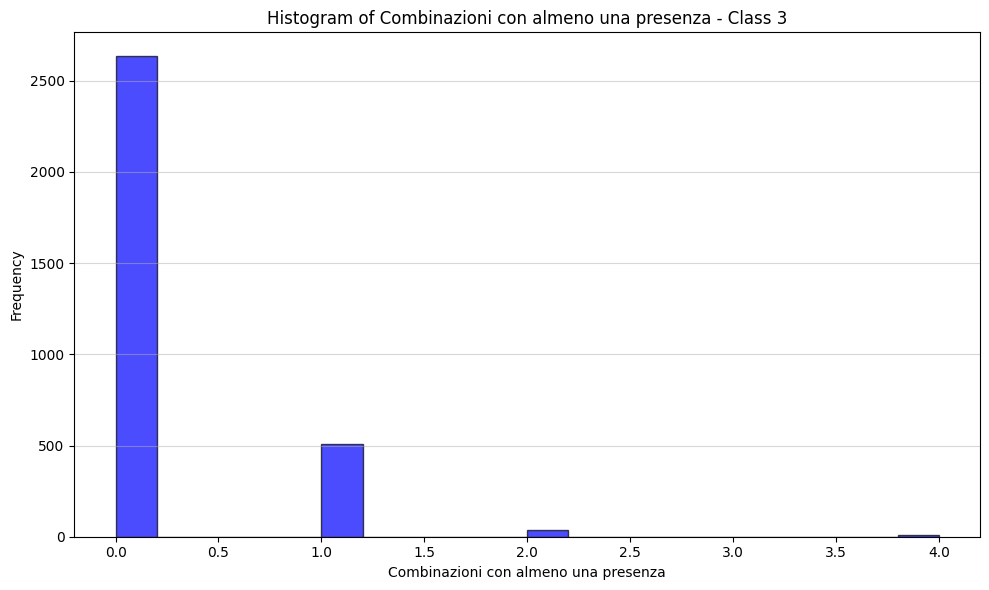

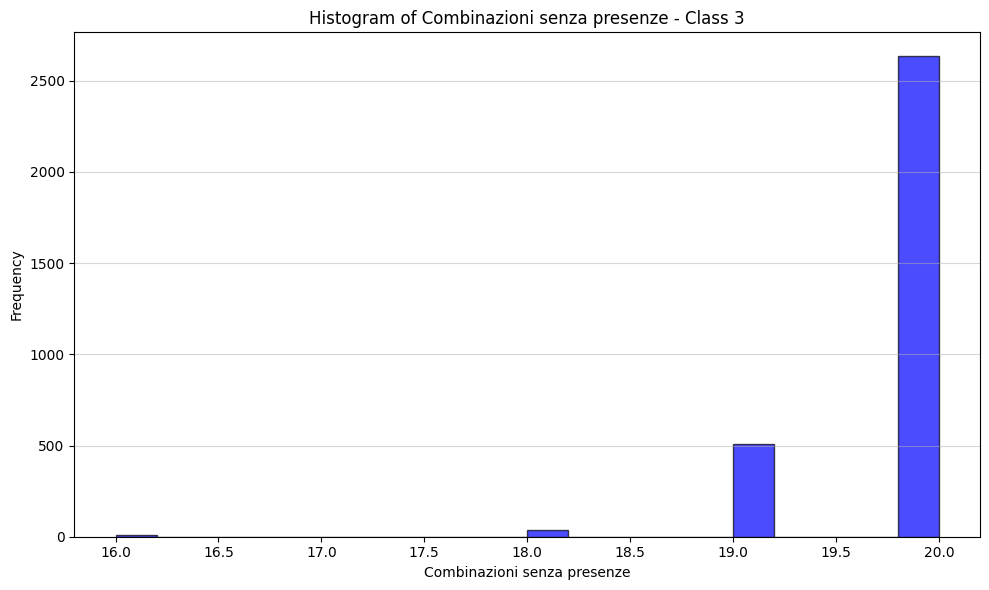

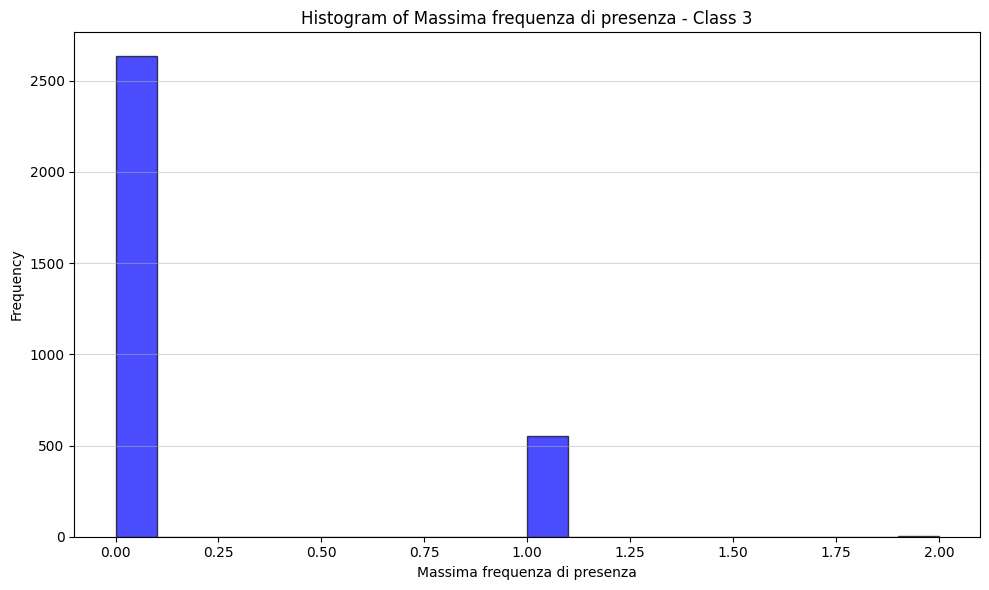

In [4]:
descr = ['Totale Presenze', 'Combinazioni con almeno una presenza', 'Combinazioni senza presenze', 'Massima frequenza di presenza'] 
k = 2
for j in range(0,4):
    data_column = [s[j] for s in sommari[k]]
    draw_histogram(data_column, k, descr[j])

In [3]:
import numpy as np

base = np.array([33, 34, 35, 58, 89, 90])

print("Base:", base)
print(base[1:])
print(base[:-1])
# Confronta ogni elemento con il successivo per verificare se la differenza è maggiore di 1
y = (base[1:] - base[:-1]) > 1
print ("y:", y)
# np.where restituisce gli indici degli elementi che soddisfano la condizione specificata
i = np.append(np.where(y), len(base) - 1)
print("i:", i)
print("boh:", np.append(-1, i))
# np.diff calcola la differenza tra elementi consecutivi di un array
# out[i] = a[i+1] - a[i]
z = np.diff(np.append(-1, i))
print("z:", z)
# np.bincount conta il numero di occorrenze di ogni valore intero in un array
b = np.bincount(z)
print("b:", b)
   
arr = np.zeros(6, dtype=int)
for i, v in enumerate(b):
    if i >= 2:
        arr[i-2] = v
arr[5] = sum(arr)
       
print("sequenze di lunghezza 2:", arr[0])
print("sequenze di lunghezza 3:", arr[1])
print("sequenze di lunghezza 4:", arr[2])
print("sequenze di lunghezza 5:", arr[3])
print("sequenze di lunghezza 6:", arr[4])
print("totale sequenze:", arr[5])

Base: [33 34 35 58 89 90]
[34 35 58 89 90]
[33 34 35 58 89]
y: [False False  True  True False]
i: [2 3 5]
boh: [-1  2  3  5]
z: [3 1 2]
b: [0 1 1 1]
sequenze di lunghezza 2: 1
sequenze di lunghezza 3: 1
sequenze di lunghezza 4: 0
sequenze di lunghezza 5: 0
sequenze di lunghezza 6: 0
totale sequenze: 2
